# 00. Dataset EDA: State Farm Distracted Driver Detection

**Owner:** Member 1 (data and leakage)

A quick look at the labeled training data before we build the splits:

1. Does the data on disk match `driver_imgs_list.csv`?
2. How many images per class?
3. How many images per driver?
4. Does every driver appear in every class?
5. Are all images the same size?
6. What do the 10 classes look like? (sample grid for the slides)
7. Why does a random split leak? (same driver vs different drivers)

Every chart is also saved to `figures/` for the slide deck.

In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image

SEED = 42


def find_repo_root(start: Path = Path.cwd()) -> Path:
    """Walk up from the notebook until we find data/driver_imgs_list.csv."""
    for folder in [start, *start.parents]:
        if (folder / "data" / "driver_imgs_list.csv").exists():
            return folder
    raise FileNotFoundError(
        "Could not find data/driver_imgs_list.csv. Unzip statefarm_train.zip into <repo>/data first."
    )


ROOT = find_repo_root()
DATA_DIR = ROOT / "data"           # on Colab: point this at wherever you unzipped statefarm_train.zip
TRAIN_DIR = DATA_DIR / "imgs" / "train"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

CLASS_NAMES = {
    "c0": "safe driving",
    "c1": "texting (right)",
    "c2": "phone call (right)",
    "c3": "texting (left)",
    "c4": "phone call (left)",
    "c5": "operating radio",
    "c6": "drinking",
    "c7": "reaching behind",
    "c8": "hair and makeup",
    "c9": "talking to passenger",
}
CLASSES = list(CLASS_NAMES)

# One shared look for every figure
BLUE, INK, MUTED, GRID, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE_RAMP = LinearSegmentedColormap.from_list("blue_ramp", ["#cde2fb", "#6da7ec", "#2a78d6", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})


def save(fig, name: str) -> None:
    path = FIG_DIR / name
    fig.savefig(path)
    print(f"saved figures/{name}")

## 1. Load the driver list and check it against the files on disk

In [2]:
df = pd.read_csv(DATA_DIR / "driver_imgs_list.csv")
df["path"] = "imgs/train/" + df["classname"] + "/" + df["img"]
df["label"] = df["classname"].str[1:].astype(int)

print(f"rows in CSV        : {len(df):,}")
print(f"classes            : {df['classname'].nunique()}  ({', '.join(sorted(df['classname'].unique()))})")
print(f"drivers (subjects) : {df['subject'].nunique()}")
print(f"duplicate filenames: {df['img'].duplicated().sum()}")
print(f"missing values     : {int(df.isna().sum().sum())}")

on_disk = {p.relative_to(DATA_DIR).as_posix() for p in TRAIN_DIR.glob("c*/*.jpg")}
in_csv = set(df["path"])
print(f"images on disk     : {len(on_disk):,}")
print(f"in CSV, not on disk: {len(in_csv - on_disk)}")
print(f"on disk, not in CSV: {len(on_disk - in_csv)}")
assert in_csv == on_disk, "CSV and image folders disagree"
df.head()

rows in CSV        : 22,424
classes            : 10  (c0, c1, c2, c3, c4, c5, c6, c7, c8, c9)
drivers (subjects) : 26
duplicate filenames: 0
missing values     : 0
images on disk     : 22,424
in CSV, not on disk: 0
on disk, not in CSV: 0


,subject,classname,img,path,label
0,p002,c0,img_44733.jpg,imgs/train/c0/img_44733.jpg,0
1,p002,c0,img_72999.jpg,imgs/train/c0/img_72999.jpg,0
2,p002,c0,img_25094.jpg,imgs/train/c0/img_25094.jpg,0
3,p002,c0,img_69092.jpg,imgs/train/c0/img_69092.jpg,0
4,p002,c0,img_92629.jpg,imgs/train/c0/img_92629.jpg,0


## 2. Images per class

If the classes are roughly balanced, plain accuracy is a fair headline number.

saved figures/eda_images_per_class.png


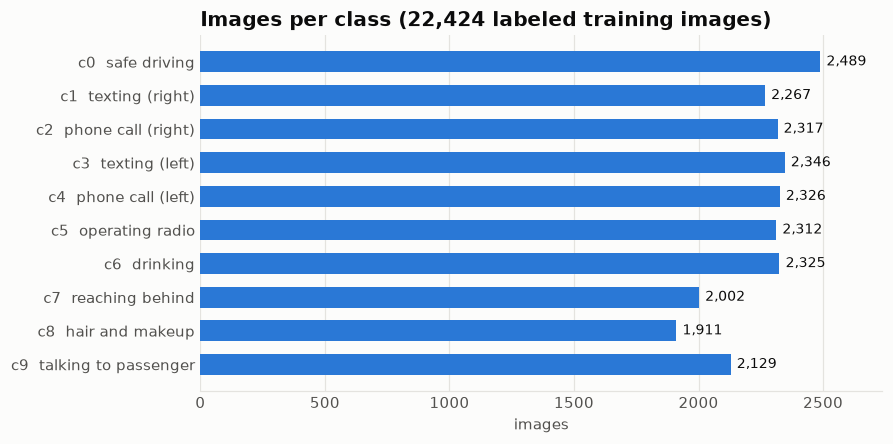

smallest class: c8 (1,911)   largest: c0 (2,489)
largest / smallest = 1.30x
share of largest class (majority-guess accuracy) = 11.1%


In [3]:
per_class = df["classname"].value_counts().reindex(CLASSES)
labels = [f"{c}  {CLASS_NAMES[c]}" for c in CLASSES]

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.barh(labels, per_class.values, height=0.62, color=BLUE)
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{v:,}" for v in per_class.values], padding=4, color=INK, fontsize=9)
ax.set_xlim(0, per_class.max() * 1.1)
ax.set_xlabel("images")
ax.set_title("Images per class (22,424 labeled training images)")
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.spines["left"].set_visible(False)
save(fig, "eda_images_per_class.png")
plt.show()

print(f"smallest class: {per_class.idxmin()} ({per_class.min():,})   largest: {per_class.idxmax()} ({per_class.max():,})")
print(f"largest / smallest = {per_class.max() / per_class.min():.2f}x")
print(f"share of largest class (majority-guess accuracy) = {per_class.max() / len(df):.1%}")

## 3. Images per driver

Drivers do not contribute equally, so holding out *N* drivers does not hold out an exact share of the images.

saved figures/eda_images_per_driver.png


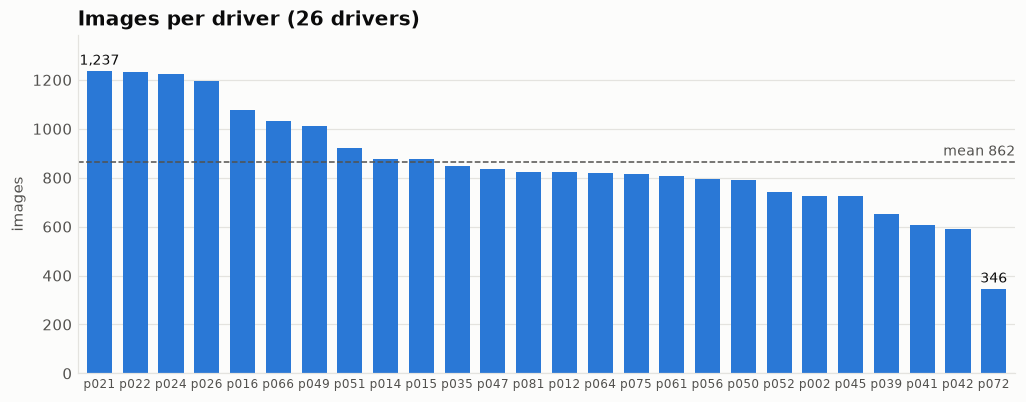

count      26.0
mean      862.5
std       214.3
min       346.0
25%       752.5
50%       823.0
75%       988.2
max      1237.0
most / fewest images = 3.6x


In [4]:
per_driver = df["subject"].value_counts().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(per_driver.index, per_driver.values, width=0.7, color=BLUE)
ax.axhline(per_driver.mean(), color=MUTED, linewidth=1, linestyle="--")
ax.text(len(per_driver) - 0.4, per_driver.mean() + 15, f"mean {per_driver.mean():.0f}",
        ha="right", va="bottom", color=MUTED, fontsize=9)
for i in (0, len(per_driver) - 1):  # label only the extremes
    ax.text(i, per_driver.iloc[i] + 12, f"{per_driver.iloc[i]:,}", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, per_driver.max() * 1.12)
ax.set_ylabel("images")
ax.set_title("Images per driver (26 drivers)")
ax.yaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.tick_params(axis="x", labelsize=8)
ax.margins(x=0.01)
save(fig, "eda_images_per_driver.png")
plt.show()

print(per_driver.describe().round(1).to_string())
print(f"most / fewest images = {per_driver.max() / per_driver.min():.1f}x")

## 4. Driver × class

For a driver-wise split to work, the held-out drivers must cover all 10 classes.

saved figures/eda_driver_by_class.png


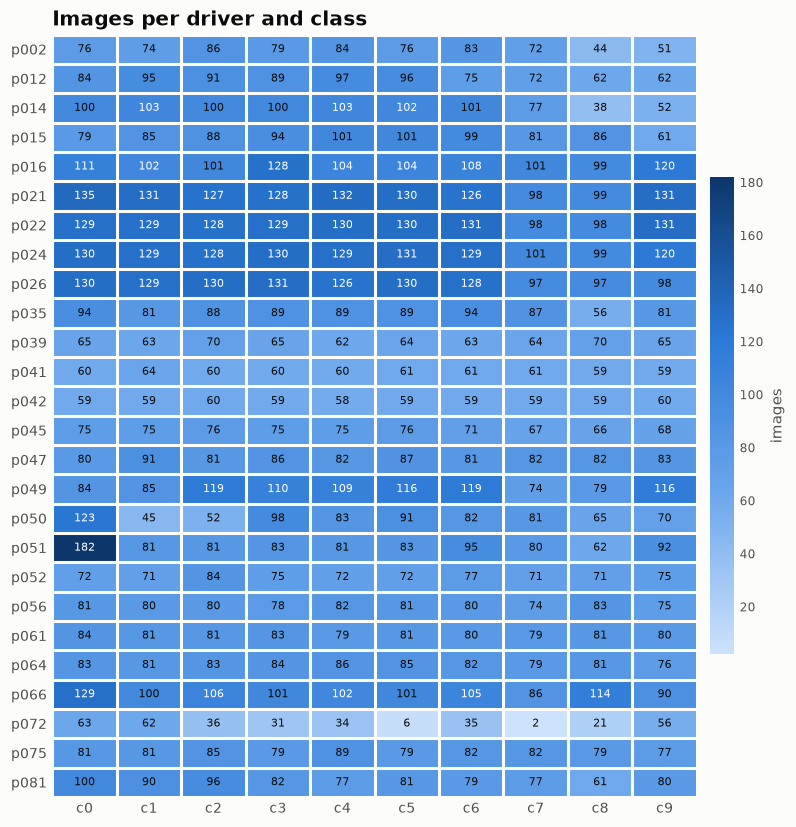

driver/class cells with zero images: 0 of 260
fewest images in one driver/class cell: 2  (('p072', 'c7'))
most images in one driver/class cell  : 182  (('p051', 'c0'))


In [5]:
grid = (df.groupby(["subject", "classname"]).size().unstack(fill_value=0)
          .reindex(columns=CLASSES).sort_index())

fig, ax = plt.subplots(figsize=(8, 9))
im = ax.imshow(grid.values, cmap=BLUE_RAMP, aspect="auto")
ax.set_xticks(range(len(CLASSES)), CLASSES)
ax.set_yticks(range(len(grid)), grid.index)
ax.tick_params(length=0, labelsize=9)
for side in ax.spines.values():
    side.set_visible(False)
threshold = grid.values.min() + 0.55 * (grid.values.max() - grid.values.min())
for r in range(grid.shape[0]):
    for c in range(grid.shape[1]):
        v = grid.values[r, c]
        ax.text(c, r, str(v), ha="center", va="center", fontsize=7.5,
                color="white" if v > threshold else INK)
ax.set_xticks(np.arange(-0.5, len(CLASSES)), minor=True)
ax.set_yticks(np.arange(-0.5, len(grid)), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=2)
ax.tick_params(which="minor", length=0)
ax.set_title("Images per driver and class")
cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.outline.set_visible(False)
cbar.ax.tick_params(length=0, labelsize=8)
cbar.set_label("images")
save(fig, "eda_driver_by_class.png")
plt.show()

print(f"driver/class cells with zero images: {(grid.values == 0).sum()} of {grid.size}")
print(f"fewest images in one driver/class cell: {grid.values.min()}  ({grid.stack().idxmin()})")
print(f"most images in one driver/class cell  : {grid.values.max()}  ({grid.stack().idxmax()})")

## 5. Image size and colour mode

Reads only the header of every image, so it is fast.

In [6]:
sizes, modes = Counter(), Counter()
for rel in df["path"]:
    with Image.open(DATA_DIR / rel) as im:
        sizes[im.size] += 1
        modes[im.mode] += 1

print("image sizes (width x height):")
for (w, h), n in sizes.most_common():
    print(f"  {w} x {h}: {n:,}")
print("colour modes:", dict(modes))

image sizes (width x height):
  640 x 480: 22,424
colour modes: {'RGB': 22424}


## 6. One example of each class

The sample grid for the dataset slide. Picks are random but fixed by the seed.

saved figures/eda_class_samples.png


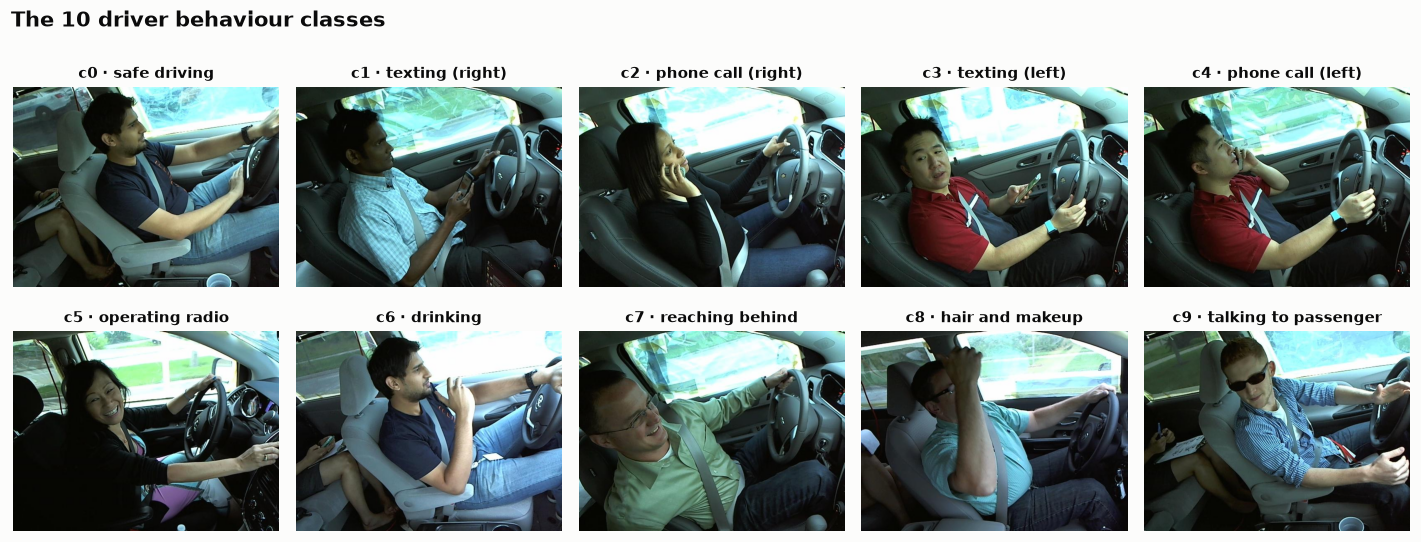

In [7]:
rng = np.random.default_rng(SEED)
picks = {c: df[df["classname"] == c].iloc[rng.integers(0, (df["classname"] == c).sum())] for c in CLASSES}

fig, axes = plt.subplots(2, 5, figsize=(13, 5.3))
for ax, c in zip(axes.flat, CLASSES):
    ax.imshow(Image.open(DATA_DIR / picks[c]["path"]))
    ax.set_title(f"{c} · {CLASS_NAMES[c]}", fontsize=10, loc="center")
    ax.axis("off")
fig.suptitle("The 10 driver behaviour classes", fontsize=14, fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
save(fig, "eda_class_samples.png")
plt.show()

## 7. Why a random split leaks

Top row: five images of **one driver** in one class. Bottom row: the same class from **five different drivers**.

Images of the same driver are near-duplicate video frames. If some of them land in training and others in
test (which is what a random split does), the model can score well by recognising the person and the
seat rather than the behaviour. A driver-wise split keeps each person entirely in one set.

saved figures/eda_same_driver_frames.png


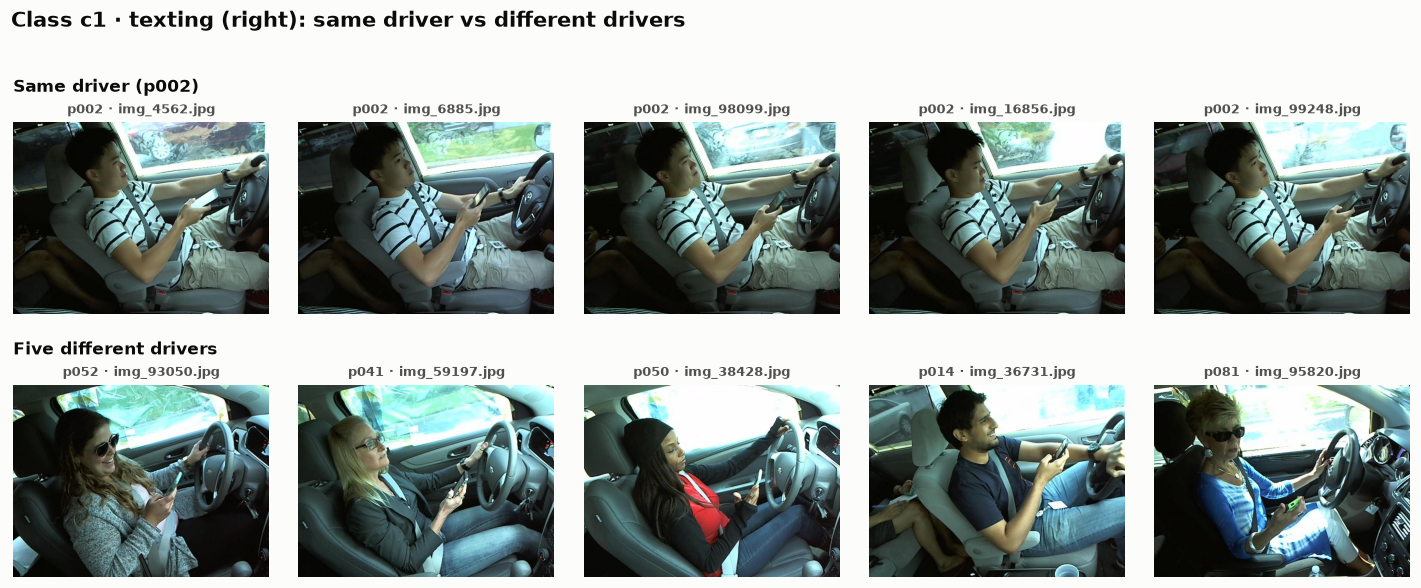

In [8]:
CLASS_FOR_DEMO = "c1"
rng = np.random.default_rng(SEED)
one_class = df[df["classname"] == CLASS_FOR_DEMO]
drivers = sorted(one_class["subject"].unique())
same_driver = one_class[one_class["subject"] == drivers[0]].sample(5, random_state=SEED)
other_drivers = pd.concat(
    one_class[one_class["subject"] == d].sample(1, random_state=SEED) for d in rng.choice(drivers[1:], 5, replace=False)
)

fig, axes = plt.subplots(2, 5, figsize=(13, 5.6))
for row, (rows_df, row_title) in enumerate([
    (same_driver, f"Same driver ({drivers[0]})"),
    (other_drivers, "Five different drivers"),
]):
    for ax, (_, r) in zip(axes[row], rows_df.iterrows()):
        ax.imshow(Image.open(DATA_DIR / r["path"]))
        ax.set_title(f"{r['subject']} · {r['img']}", fontsize=8.5, color=MUTED, loc="center")
        ax.axis("off")
    axes[row, 0].text(0, 1.16, row_title, transform=axes[row, 0].transAxes, fontsize=11, fontweight="bold")
fig.suptitle(f"Class {CLASS_FOR_DEMO} · {CLASS_NAMES[CLASS_FOR_DEMO]}: same driver vs different drivers",
             fontsize=14, fontweight="bold", x=0.01, ha="left", y=1.02)
fig.tight_layout()
save(fig, "eda_same_driver_frames.png")
plt.show()

## Takeaways

| Question | Answer |
|---|---|
| Does the CSV match the disk? | Yes. 22,424 rows, 22,424 images, no duplicates, nothing missing. |
| Classes | 10, roughly balanced: 1,911 (c8) to 2,489 (c0), a 1.30× spread. |
| Drivers | 26, uneven: 346 images (p072) to 1,237 (p021), a 3.6× spread. Mean 862. |
| Does every driver cover every class? | Yes, 0 empty cells out of 260. But p072 has only 2 images of c7 and 6 of c5. |
| Image format | All 640 × 480, RGB. |

**What this means for the splits and `data.py`:**

- **Accuracy is a fair headline metric.** Always guessing the biggest class scores only 11.1%, so there is no
  majority-class shortcut. We still report macro-F1 as planned.
- **Holding out N drivers is not the same as holding out N/26 of the images.** Drivers differ by up to 3.6× in
  image count, so the split script should print the actual image share of train / val / test.
- **Keep p072 in training.** With 2 and 6 images in two classes, it is a poor validation or test driver.
- **Resizing to 224 × 224 squashes the 4:3 frame to a square.** That is fine as long as every model gets the
  same resize, which is why it lives in the shared `data.py`.
- **Same-driver frames are near-duplicates (section 7).** This is the leakage that Experiment 3 measures.